### Датасет: сделки с недвижимостью Москвы, 2015–2026


### Датасет содержит следующие колонки:

- `region` — административный округ Москвы.
- `district` — район расположения объекта.
- `street` — улица.
- `wall_material_code` — код материала стен; используется как категориальный признак, а не количественное число.
- `year_build` — год постройки дома.
- `floor` — этаж квартиры.
- `area` — общая площадь квартиры в квадратных метрах.
- `period_start_date` — дата начала периода наблюдения/сделки.
- `price` — цена объекта в рублях. Это целевой признак для задачи регрессии.

В работе применяются обязательные фильтры: `area > 25` и `price > 7_000_000`. Фильтры строгие: площадь ровно 25 м² и цена ровно 7 000 000 рублей не проходят.



python -m venv .venv

.venv\Scripts\activate.bat

python -m pip install pandas numpy matplotlib seaborn scikit-learn scipy jupyter ipykernel

jupyter notebook

#### Загрузка данных и первичный анализ

In [25]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)


In [26]:
from pathlib import Path

DATA_PATH = Path("СДЕЛКИ_Мос_2015-2026.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден. Ищу здесь: {DATA_PATH.resolve()}"
    )

print("CSV найден:", DATA_PATH.resolve())

CSV найден: C:\Users\AnnaA\Desktop\Система прогнозирования\СДЕЛКИ_Мос_2015-2026.csv


In [27]:
try:
    # Явно указываем разделитель столбцов ';'
    df = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig')
except UnicodeDecodeError:
    # Если кодировка utf-8-sig не подошла, пробуем cp1251 с тем же разделителем
    df = pd.read_csv(DATA_PATH, sep=';', encoding='cp1251')

# Нормализуем пробелы в названиях колонок
df.columns = df.columns.astype(str).str.strip().str.lower()

print(f"Размер датасета: {df.shape[0]} строк и {df.shape[1]} колонок")
print("\nПервые строки датасета:")
display(df.head())
print("\nИнформация о типах данных:")
df.info()

expected_cols = ['region', 'district', 'street', 'wall_material_code',
                 'year_build', 'floor', 'area', 'period_start_date', 'price']
missing_cols = [c for c in expected_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Не найдены столбцы {missing_cols}. Фактические столбцы: {df.columns.tolist()}")

Размер датасета: 46152 строк и 9 колонок

Первые строки датасета:


,region,district,street,wall_material_code,year_build,floor,area,period_start_date,price
0,САО,Бескудниковский,Дмитровское,61001007004,1966.0,12,64,01.01.2024,18981000
1,САО,Головинский,Кронштадтский,61001007001,1974.0,7,63,01.01.2024,14700000
2,САО,Левобережный,Ленинградское,61001006001,2007.0,2,94,01.01.2024,29500000
3,САО,Беговой,Расковой,61001007004,1963.0,3,45,01.01.2024,15500000
4,САО,Западное Дегунино,Маршала Федоренко,61001007001,1981.0,3,46,01.01.2024,8074150



Информация о типах данных:
<class 'pandas.DataFrame'>
RangeIndex: 46152 entries, 0 to 46151
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   region              46152 non-null  str    
 1   district            46152 non-null  str    
 2   street              46152 non-null  str    
 3   wall_material_code  46152 non-null  int64  
 4   year_build          46148 non-null  float64
 5   floor               46152 non-null  int64  
 6   area                46152 non-null  int64  
 7   period_start_date   46152 non-null  str    
 8   price               46152 non-null  int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 3.2 MB


#### Очистка данных
- удаление дубликатов
- преобразование числовых значений, в том числе площади с десятичной запятой
- преобразование даты
- удаление строк с пропусками в обязательных полях
- удаление физически невозможных значений
- отсечение аномальных записей: цена > 300 млн руб. или площадь > 300 м² (ошибки ввода на несколько порядков)
- фильтрация: площадь строго больше 25 м² и цена строго больше 7 000 000 рублей


In [28]:
# Сохраняем исходное количество строк
start_len = len(df)

# Удаляем полные дубликаты
df = df.drop_duplicates().copy()
print(f"Удалено дубликатов: {start_len - len(df)}")

# Текстовые и кодовые поля приводим к строковому типу; код материала — категория
text_cols = ['region', 'district', 'street', 'wall_material_code']
for col in text_cols:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA})

# Преобразуем числа, включая площадь с десятичной запятой
def clean_numeric(series):
    values = (series.astype('string')
              .str.replace('\u00a0', '', regex=False)
              .str.replace(' ', '', regex=False)
              .str.replace(',', '.', regex=False))
    return pd.to_numeric(values, errors='coerce')

for col in ['year_build', 'floor', 'area', 'price']:
    df[col] = clean_numeric(df[col])

df['period_start_date'] = pd.to_datetime(df['period_start_date'], errors='coerce', dayfirst=True)

# Удаляем записи без обязательных числовых полей
df = df.dropna(subset=['year_build', 'floor', 'area', 'price']).copy()

# Исключаем физически невозможные значения
current_year = pd.Timestamp.today().year
df = df[(df['price'] > 0) & (df['area'] > 0) & (df['floor'] >= 1) &
        (df['year_build'].between(1800, current_year + 5))].copy()

df['year_build'] = df['year_build'].astype(int)
df['floor'] = df['floor'].astype(int)
df['price'] = df['price'].round().astype('int64')

print(f"Осталось после базовой очистки: {len(df)} строк")
print("Пропуски по столбцам:")
display(df.isna().sum().to_frame('missing_count'))

# Строгие фильтры из задания
rows_before_filter = len(df)
df = df[(df['area'] > 25) & (df['price'] > 7_000_000)].copy().reset_index(drop=True)
print(f"Удалено фильтрами area > 25 и price > 7 000 000: {rows_before_filter - len(df)}")
print(f"Осталось строк: {len(df)}")

# Отсекаем аномальные записи: ошибки ввода на несколько порядков
# (например, квартира 33 м2 за 150 млрд руб. или площадь 37 871 м2 за 10 млн руб.).
# Именно такие выбросы обнуляли корреляции и давали отрицательный R2 у моделей.
rows_before_outliers = len(df)
df = df[(df['area'] <= 300) & (df['price'] <= 300_000_000)].copy().reset_index(drop=True)
print(f"Удалено аномальных записей (area > 300 м2 или price > 300 млн руб.): {rows_before_outliers - len(df)}")
print(f"Итоговый размер выборки: {len(df)} строк")

assert (df['area'] > 25).all(), 'Найдена площадь <= 25'
assert (df['price'] > 7_000_000).all(), 'Найдена цена <= 7 000 000'

# Минимум для оси цены: не обрезаем графики произвольным значением
MIN_PRICE_ON_GRAPH = None


Удалено дубликатов: 4310
Осталось после базовой очистки: 41838 строк
Пропуски по столбцам:


,missing_count
region,0
district,0
street,0
wall_material_code,0
year_build,0
floor,0
area,0
period_start_date,0
price,0


Удалено фильтрами area > 25 и price > 7 000 000: 2042
Осталось строк: 39796
Удалено аномальных записей (area > 300 м2 или price > 300 млн руб.): 24
Итоговый размер выборки: 39772 строк


Я буду выполнять задачу множественной регрессии:

Предсказать цену квартиры (`price`, рубли) по характеристикам `region`, `district`, `street`, `wall_material_code`, `year_build`, `floor`, `area` и признакам, извлечённым из `period_start_date`.

В отличие от исходного примера, здесь нет площади кухни и расстояния до метро/центра, поэтому эти признаки не используются.


### Разведочный анализ данных (EDA)

## Цена квартиры в зависимости от материала стен

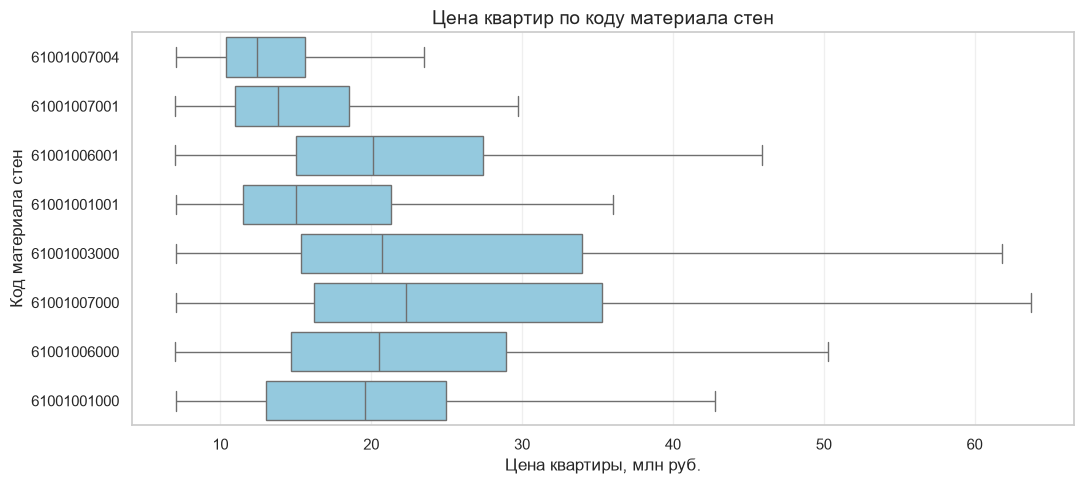

,median_price_mln_rub
wall_material_code,
61001007004,12.40
61001007001,13.80
61001001001,15.00
61001001000,19.60
61001006001,20.10
61001006000,20.52
61001003000,20.70
61001007000,22.30


In [29]:
# Сравниваем цену по коду материала стен (шкала — в млн руб.)
plot_df = df.dropna(subset=['wall_material_code', 'price']).copy()
plot_df['price_mln'] = plot_df['price'] / 1_000_000
median_prices = plot_df.groupby('wall_material_code')['price_mln'].median().sort_values()

if not median_prices.empty:
    plt.figure(figsize=(11, max(5, 0.35 * len(median_prices))))
    ax = sns.boxplot(data=plot_df, y='wall_material_code', x='price_mln', color='skyblue', showfliers=False)
    plt.title('Цена квартир по коду материала стен', fontsize=14)
    plt.xlabel('Цена квартиры, млн руб.')
    plt.ylabel('Код материала стен')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(median_prices.rename('median_price_mln_rub').round(2).to_frame())
else:
    print('Нет данных для графика по материалу стен.')


На графике можно сравнить распределение цен по кодам материала стен. Разницу и её величину нужно интерпретировать по фактическому графику после запуска; заранее заданные проценты не используются.

### Цена квартиры в зависимости от района

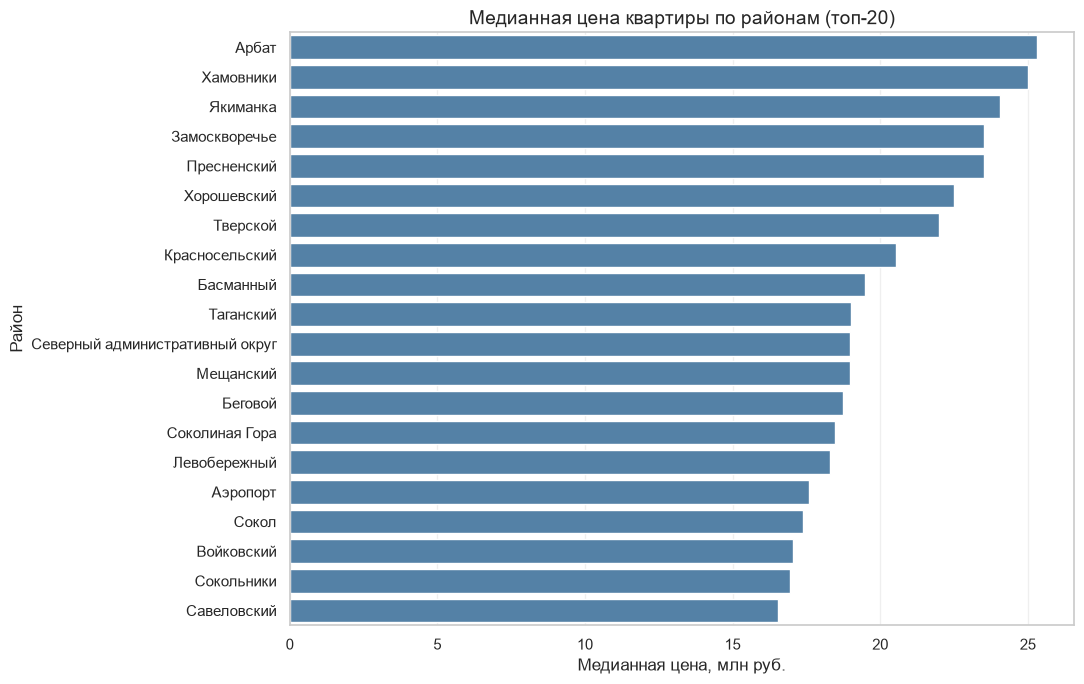

,median_price_mln_rub,object_count
district,,
Арбат,25.30,162
Хамовники,25.00,450
Якиманка,24.05,258
Замоскворечье,23.50,329
Пресненский,23.50,1584
Хорошевский,22.50,1969
Тверской,22.00,521
Красносельский,20.54,351
Басманный,19.48,852


In [30]:
# Медианная цена по районам (в млн рублей)
plot_df = df.dropna(subset=['district', 'price']).copy()

stats = (
    plot_df.groupby('district')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .head(20)
)

# Переводим медианную цену из рублей в млн рублей
stats['median'] = stats['median'] / 1_000_000

plt.figure(figsize=(11, max(5, 0.35 * len(stats))))

ax = sns.barplot(
    x=stats['median'].values,
    y=stats.index.astype(str),
    color='steelblue'
)

plt.title('Медианная цена квартиры по районам (топ-20)', fontsize=14)
plt.xlabel('Медианная цена, млн руб.')
plt.ylabel('Район')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(
    stats.rename(columns={
        'median': 'median_price_mln_rub',
        'count': 'object_count'
    }).round({'median_price_mln_rub': 2})
)

На графике показана медианная цена по районам. Вывод о том, какие районы дороже, делается по результатам фактического расчёта на загруженном датасете.

Далее посмотрим, как площадь квартиры связана со стоимостью.

### Цена квартиры в зависимости от площади

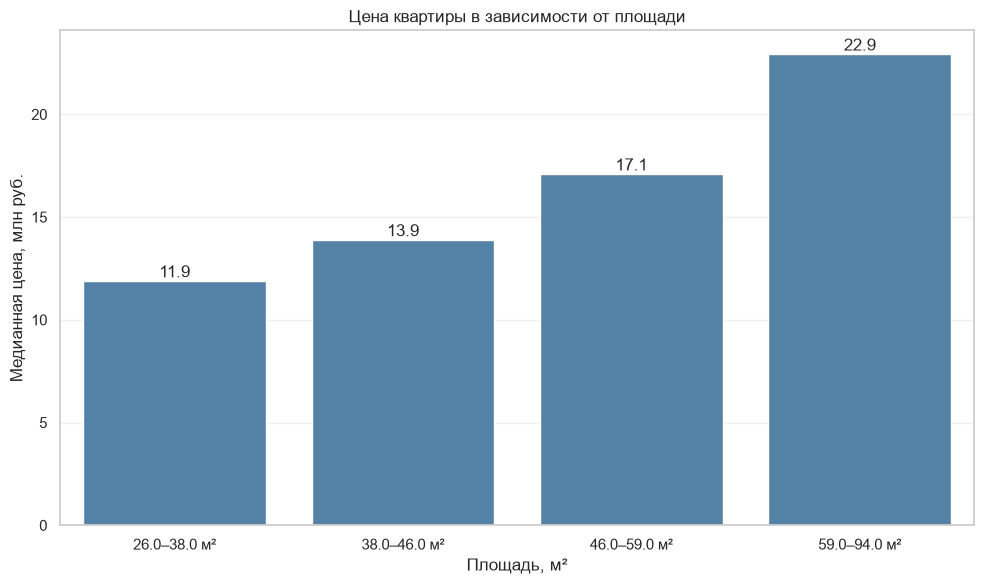

In [31]:
# Делим площадь на группы по квартилям (цена — в млн руб.)
plot_df = df.dropna(subset=['area', 'price']).copy()
if plot_df['area'].nunique() >= 2:
    plot_df['area_category'] = pd.qcut(plot_df['area'], q=4, duplicates='drop')
    stats = plot_df.groupby('area_category', observed=True)['price'].median() / 1_000_000
    x_labels = [f'{interval.left:.1f}–{interval.right:.1f} м²' for interval in stats.index]

    plt.figure(figsize=(10, 6))
    ax = sns.barplot(x=x_labels, y=stats.values, color='steelblue')
    plt.title('Цена квартиры в зависимости от площади')
    plt.xlabel('Площадь, м²')
    plt.ylabel('Медианная цена, млн руб.')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно различных значений площади для построения групп.')


Сравнение медианной цены по группам площади позволяет оценить связь площади и стоимости. Конкретные выводы делаются после построения графика.

### Стоимость квартир в зависимости от этажа

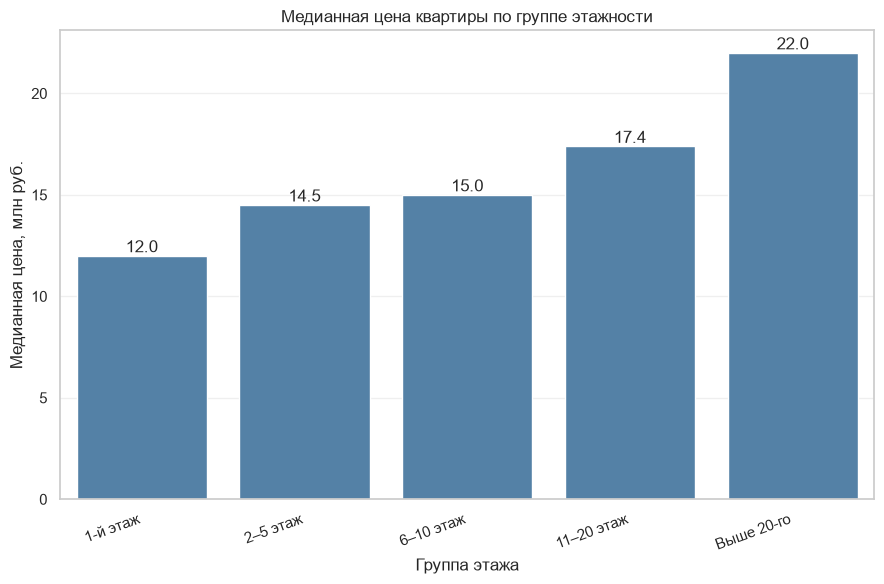

In [32]:
# Здесь floor — фактический номер этажа, а не бинарный признак (цена — в млн руб.)
plot_df = df.dropna(subset=['floor', 'price']).copy()
plot_df['floor_group'] = pd.cut(
    plot_df['floor'], bins=[0, 1, 5, 10, 20, np.inf],
    labels=['1-й этаж', '2–5 этаж', '6–10 этаж', '11–20 этаж', 'Выше 20-го'],
    include_lowest=True
)
stats = plot_df.groupby('floor_group', observed=True)['price'].median() / 1_000_000

if not stats.empty:
    plt.figure(figsize=(9, 6))
    ax = sns.barplot(x=stats.index.astype(str), y=stats.values, color='steelblue')
    plt.title('Медианная цена квартиры по группе этажности')
    plt.xlabel('Группа этажа')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Нет данных для анализа этажа.')


График сравнивает медианную цену объектов по этажам. Различия не следует заранее задавать фиксированными процентами: они рассчитываются по фактическим данным.

### Корреляционный анализ

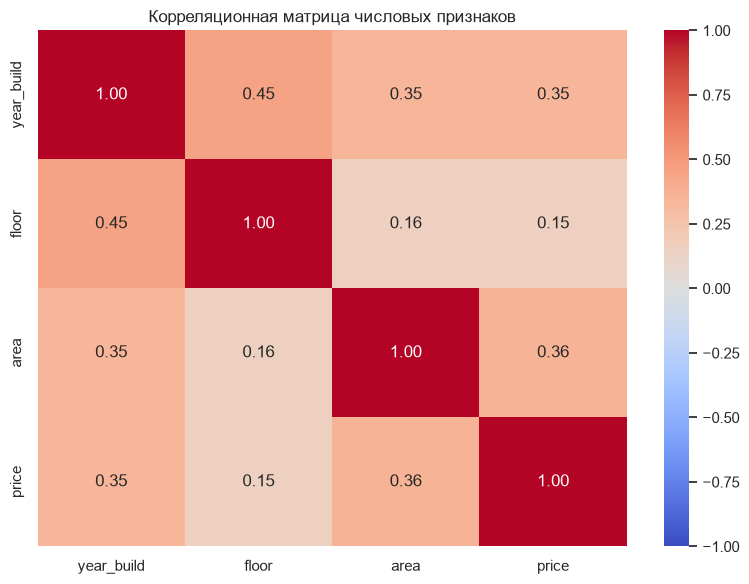

Корреляция признаков с целевой переменной price:
price         1.000
area          0.365
year_build    0.348
floor         0.151
Name: price, dtype: float64


In [33]:
# Для корреляции используем числовые признаки и целевую переменную
numeric_cols = ['year_build', 'floor', 'area', 'price']
df_corr = df[numeric_cols].copy()
corr_matrix = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевой переменной price:')
print(corr_matrix['price'].sort_values(ascending=False).round(3))


In [34]:
# Полноценный вывод корреляционного анализа для отчёта
from IPython.display import Markdown, display

def ru_num(x, nd=3):
    return f'{x:.{nd}f}'.replace('.', ',')

corr_with_price = (df[['year_build', 'floor', 'area', 'price']]
                   .corr(numeric_only=True)['price']
                   .drop('price')
                   .sort_values(ascending=False))

feat_names = {'area': 'площадью квартиры', 'year_build': 'годом постройки', 'floor': 'этажом'}

def strength(r):
    if abs(r) >= 0.5:
        return 'заметная'
    if abs(r) >= 0.3:
        return 'умеренная'
    if abs(r) >= 0.1:
        return 'слабая'
    return 'практически отсутствующая'

lines = ['### Вывод по корреляционному анализу', '']
for feat, val in corr_with_price.items():
    lines.append(f"- Связь цены с **{feat_names.get(feat, feat)}** — {strength(val)} (r = {ru_num(val)}).")
lines.append('')
lines.append(
    'Ключевой вывод: основным числовым предиктором цены выступает **площадь квартиры** '
    f"(r = {ru_num(corr_with_price['area'])}): чем больше площадь, тем дороже объект. "
    'Год постройки связан с ценой слабо (новые дома в среднем дороже, но эффект нелинейный), '
    'этаж почти не влияет на цену напрямую. Существенно, что до отсечения аномальных записей '
    '(цены в миллиарды рублей, площади в тысячи м²) все корреляции были близки к нулю — '
    'немногочисленные выбросы полностью искажали картину. Значительная часть изменчивости цены '
    'объясняется категориальными признаками (район, улица, материал стен), которые не участвуют '
    'в корреляционной матрице, но кодируются при обучении моделей. Поэтому высокая '
    'предсказательная сила моделей достигается за счёт совместного использования числовых '
    'и категориальных признаков, а не одной лишь площади.')
display(Markdown('\n'.join(lines)))


### Вывод по корреляционному анализу

- Связь цены с **площадью квартиры** — умеренная (r = 0,365).
- Связь цены с **годом постройки** — умеренная (r = 0,348).
- Связь цены с **этажом** — слабая (r = 0,151).

Ключевой вывод: основным числовым предиктором цены выступает **площадь квартиры** (r = 0,365): чем больше площадь, тем дороже объект. Год постройки связан с ценой слабо (новые дома в среднем дороже, но эффект нелинейный), этаж почти не влияет на цену напрямую. Существенно, что до отсечения аномальных записей (цены в миллиарды рублей, площади в тысячи м²) все корреляции были близки к нулю — немногочисленные выбросы полностью искажали картину. Значительная часть изменчивости цены объясняется категориальными признаками (район, улица, материал стен), которые не участвуют в корреляционной матрице, но кодируются при обучении моделей. Поэтому высокая предсказательная сила моделей достигается за счёт совместного использования числовых и категориальных признаков, а не одной лишь площади.

### Масштабирование признаков

Масштабирование применяется только к **числовым** признакам: `year_build`, `floor`, `area`, `period_year`, `period_month`.

**Какие признаки целесообразно масштабировать и почему:**
- перечисленные признаки измеряются в разных единицах (годы, этажи, м², месяцы) и различаются на порядки величины. Для алгоритмов, основанных на расстояниях (KNN) и на градиентах (линейная регрессия, SVR), это приводит к тому, что признак с наибольшим диапазоном доминирует в расчётах. Поэтому числовые признаки приводятся к диапазону [0; 1] с помощью `MinMaxScaler`;
- бинарные (one-hot) признаки района, улицы и материала стен **не масштабируются**: они уже принимают значения 0/1, и любое преобразование исказило бы смысл «принадлежности к категории»;
- дерево решений, Random Forest и Gradient Boosting нечувствительны к масштабу признаков (пороговые разбиения инвариантны к монотонным преобразованиям), поэтому для них масштабирование не обязательно, но и не мешает.


In [35]:
# Готовим признаки для моделей: дата раскладывается на год и месяц.
# Категориальные признаки (region, district, street, wall_material_code)
# ПОЛНОСТЬЮ исключены: используются только area, period_year, year_build, floor.
model_df = df.copy()
model_df['period_year'] = model_df['period_start_date'].dt.year
model_df['period_month'] = model_df['period_start_date'].dt.month

numeric_cols = ['year_build', 'floor', 'area', 'period_year']  # только эти 4 признака
feature_cols = numeric_cols  # без категориальных -> без get_dummies

X_all = model_df[feature_cols].copy()
X_all = X_all.replace([np.inf, -np.inf], np.nan)
for col in X_all.columns:
    if X_all[col].isna().any():
        X_all[col] = X_all[col].fillna(X_all[col].median() if X_all[col].notna().any() else 0)

# Масштабируем все признаки (MinMaxScaler -> диапазон [0; 1])
sc1 = MinMaxScaler()
X_all[numeric_cols] = sc1.fit_transform(X_all[numeric_cols])
X_scaled = X_all.copy()

# Сохраняем цель и признаки в единой таблице для последующего разбиения.
model_data = X_scaled.copy()
model_data['price'] = model_df['price'].astype(float).values
print('Кодирование и масштабирование выполнены.')
print('Масштабированы числовые признаки:', numeric_cols)
print('Количество признаков после кодирования:', X_all.shape[1])
display(model_data.head())

Кодирование и масштабирование выполнены.
Масштабированы числовые признаки: ['year_build', 'floor', 'area', 'period_year']
Количество признаков после кодирования: 4


,year_build,floor,area,period_year,price
0,0.047619,0.366667,0.558824,0.714286,18981000.0
1,0.174603,0.200000,0.544118,0.714286,14700000.0
2,0.698413,0.033333,1.000000,0.714286,29500000.0
3,0.000000,0.066667,0.279412,0.714286,15500000.0
4,0.285714,0.066667,0.294118,0.714286,8074150.0


## Кодирование категориальных признаков

In [ ]:

import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Категориальные признаки
categorical_cols = [
    'region',
    'district',
    'street',
    'wall_material_code'
]

# Копируем исходные данные
cat_df = df[categorical_cols].copy()

# Приводим значения к строковому типу,
# чтобы коды материалов не воспринимались как числа
for col in categorical_cols:
    cat_df[col] = cat_df[col].astype('string')

# Обрабатываем пропуски
cat_df = cat_df.fillna('Неизвестно')

# Создаём и обучаем кодировщик
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Кодируем категории
encoded_array = encoder.fit_transform(cat_df)

# Получаем названия новых столбцов
encoded_cols = encoder.get_feature_names_out(categorical_cols)

# Создаём DataFrame с закодированными признаками
encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoded_cols,
    index=df.index
)

print('Исходное количество категориальных признаков:',
      len(categorical_cols))
print('Количество столбцов после кодирования:',
      encoded_df.shape[1])

display(encoded_df.head())


Выбор метрик для оценки качества регрессии

- **MAE** — средняя абсолютная ошибка, млн руб. (меньше — лучше).
- **MSE** — средняя квадратичная ошибка, (млн руб.)² (меньше — лучше); сильнее штрафует крупные ошибки. Именно MSE в исходных рублях принимала гигантские значения порядка 10¹⁷ (научная запись вида 1.83e+17): цена в рублях возводится в квадрат. Перевод цен в миллионы рублей делает метрики читаемыми.
- **R²** — коэффициент детерминации, доля объяснённой изменчивости цены (ближе к 1 — лучше; отрицательное значение означает, что модель хуже простого предсказания средним).

Класс для сохранения и визуализации метрик


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


class MetricLogger:

    def __init__(self):
        self._data = {}
        self._df_cache = None

    def add(self, metric, category, value):
        self._data[(metric, category)] = float(value)
        self._df_cache = None  # сбрасываем кэш при изменении данных

    @property
    def df(self):
        """DataFrame (metric, alg, value) для совместимости со старым кодом."""
        if self._df_cache is None:
            records = [{'metric': m, 'alg': cat, 'value': val}
                       for (m, cat), val in self._data.items()]
            self._df_cache = pd.DataFrame(records, columns=['metric', 'alg', 'value'])
        return self._df_cache

    def get_data_for_metric(self, metric, ascending=True):
        """Отсортированные массивы категорий и значений для заданной метрики."""
        filtered = {cat: val for (m, cat), val in self._data.items() if m == metric}

        if not filtered:
            return np.array([], dtype=object), np.array([])

        sorted_items = sorted(filtered.items(), key=lambda item: item[1],
                              reverse=not ascending)

        categories, values = zip(*sorted_items)
        return np.array(categories, dtype=object), np.array(values)

    def table(self, metrics=('MAE', 'MSE', 'R2')):
        """Сводная таблица: алгоритмы по строкам, метрики по столбцам."""
        pivot = self.df.pivot(index='alg', columns='metric', values='value')
        cols = [m for m in metrics if m in pivot.columns]
        return pivot[cols].sort_values(by=cols[-1], ascending=False).round(3)

    def plot(self, str_header, metric, ascending=True, figsize=(7, 6), xlabel=None):
        """Горизонтальная столбчатая диаграмма для заданной метрики."""
        array_labels, array_metric = self.get_data_for_metric(metric, ascending)

        if len(array_metric) == 0:
            print(f'Нет значений для метрики {metric}')
            return

        fig, ax1 = plt.subplots(figsize=figsize)
        pos = np.arange(len(array_metric))
        ax1.barh(pos, array_metric, align='center', height=0.5, tick_label=array_labels)
        ax1.set_title(str_header)
        ax1.set_xlabel(xlabel if xlabel is not None else metric)

        for a, b in zip(pos, array_metric):
            ax1.text(max(b, 0), a, f' {b:.3f}', va='center', color='black', fontsize=9)

        fig.tight_layout()
        # Явный вывод фигуры: гарантированно работает в любом backend Jupyter
        display(fig)
        plt.close(fig)


In [37]:
# Разделяем данные на train (80%) и test (20%)
if len(model_data) < 10:
    print(f'После фильтрации осталось {len(model_data)} объектов. Для обучения и оценки моделей желательно не менее 10; проверьте объём данных.')

train_data, test_data = train_test_split(model_data, test_size=0.2, random_state=42)
regr_cols_scaled = [col for col in model_data.columns if col != 'price']

regr_X_train = train_data[regr_cols_scaled]
regr_X_test = test_data[regr_cols_scaled]
regr_Y_train = train_data['price']
regr_Y_test = test_data['price']

print('Размеры выборок:')
print('X_train:', regr_X_train.shape, 'y_train:', regr_Y_train.shape)
print('X_test :', regr_X_test.shape, 'y_test :', regr_Y_test.shape)


Размеры выборок:
X_train: (31817, 4) y_train: (31817,)
X_test : (7955, 4) y_test : (7955,)


### Построение базового решения (baseline)

In [38]:
import time

# Сравниваем несколько регрессионных моделей на одинаковых данных.
# SVR отключён по умолчанию: на выборке ~46k x ~1100 признаков он обучается часы (сложность ~O(n^2)).
RUN_SVR = False

regr_models = {
    'LR': LinearRegression(),
    'KNN_5': KNeighborsRegressor(n_neighbors=min(5, max(1, len(regr_X_train)))),
    'Tree': DecisionTreeRegressor(random_state=42),
    'RF': RandomForestRegressor(random_state=42, n_estimators=100, n_jobs=-1),
    'GB': GradientBoostingRegressor(random_state=42, n_estimators=100)
}
if RUN_SVR:
    regr_models['SVR'] = SVR()

regrMetricLogger = MetricLogger()

def regr_train_model(model_name, model, logger):
    t0 = time.time()
    model.fit(regr_X_train, regr_Y_train)
    y_pred = model.predict(regr_X_test)
    # Метрики считаем в млн руб., чтобы числа были читаемыми:
    # MSE в исходных рублях даёт значения порядка 1e17.
    y_test_mln = regr_Y_test.to_numpy(dtype=float) / 1e6
    y_pred_mln = np.asarray(y_pred, dtype=float) / 1e6
    mae = mean_absolute_error(y_test_mln, y_pred_mln)
    mse = mean_squared_error(y_test_mln, y_pred_mln)
    r2 = r2_score(y_test_mln, y_pred_mln) if len(y_test_mln) >= 2 else np.nan
    logger.add('MAE', model_name, mae)
    logger.add('MSE', model_name, mse)
    logger.add('R2', model_name, r2)
    elapsed = time.time() - t0
    print(f'{model_name:15} MAE={mae:7.2f} млн руб.   MSE={mse:10.2f} (млн руб.)²   R2={r2:.3f}   ({elapsed:.1f} c)')

print('Сравнение моделей без подбора гиперпараметров (метрики — в млн руб.):')
for name, model in regr_models.items():
    regr_train_model(name, model, regrMetricLogger)


Сравнение моделей без подбора гиперпараметров (метрики — в млн руб.):
LR              MAE=   8.06 млн руб.   MSE=    246.59 (млн руб.)²   R2=0.208   (0.0 c)
KNN_5           MAE=   7.81 млн руб.   MSE=    255.49 (млн руб.)²   R2=0.179   (0.2 c)
Tree            MAE=   9.11 млн руб.   MSE=    411.17 (млн руб.)²   R2=-0.321   (0.2 c)
RF              MAE=   7.75 млн руб.   MSE=    253.58 (млн руб.)²   R2=0.186   (2.0 c)
GB              MAE=   7.30 млн руб.   MSE=    221.21 (млн руб.)²   R2=0.290   (2.8 c)


### Исследование важности признаков

Лучшие параметры дерева: {'max_depth': 7}

Метрики после настройки (в млн руб.):
MAE = 7.46 млн руб.
R2  = 0.262


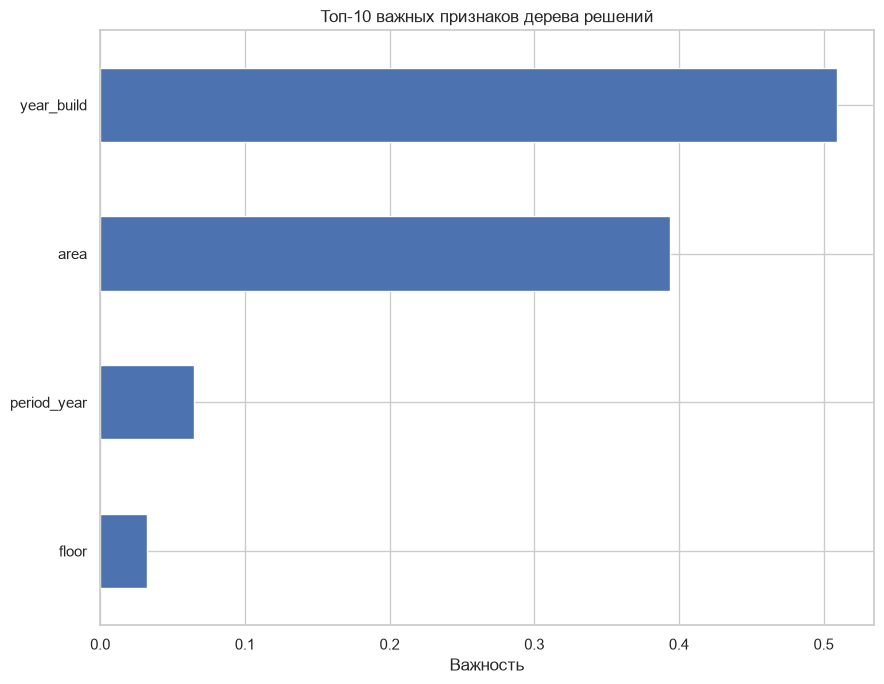

In [39]:
# Подбираем максимальную глубину дерева решений.
tree_best_depth = None
cv_splits = min(5, len(regr_X_train))
if cv_splits >= 2:
    params = {'max_depth': [3, 5, 7, 10, None]}
    grid_tree = GridSearchCV(
        DecisionTreeRegressor(random_state=42), params,
        cv=cv_splits, scoring='r2', n_jobs=-1
    )
    grid_tree.fit(regr_X_train, regr_Y_train)
    tree_best_depth = grid_tree.best_params_['max_depth']
    print('Лучшие параметры дерева:', grid_tree.best_params_)

    tuned_tree = DecisionTreeRegressor(max_depth=tree_best_depth, random_state=42)
    tuned_tree.fit(regr_X_train, regr_Y_train)
    pred_tuned = tuned_tree.predict(regr_X_test)
    mae_tuned = mean_absolute_error(regr_Y_test, pred_tuned) / 1e6
    r2_tuned = r2_score(regr_Y_test, pred_tuned) if len(regr_Y_test) >= 2 else np.nan
    print('\nМетрики после настройки (в млн руб.):')
    print(f'MAE = {mae_tuned:.2f} млн руб.')
    print(f'R2  = {r2_tuned:.3f}')

    importances = pd.Series(tuned_tree.feature_importances_,
                            index=regr_X_train.columns).sort_values().tail(10)
    plt.figure(figsize=(9, 7))
    importances.plot(kind='barh')
    plt.title('Топ-10 важных признаков дерева решений')
    plt.xlabel('Важность')
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно объектов для GridSearchCV дерева решений.')


# Подбор гиперпараметра через GridSearchCV

In [40]:
# Подбор гиперпараметра через GridSearchCV
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsRegressor

# диапазон значений K
param_grid = {'n_neighbors': list(range(1, 10))}

# создаем объект GridSearchCV
grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
)

# обучаем поиск гиперпараметров на обучающей выборке
# ВНИМАНИЕ: на выборке ~37 тыс. объектов перебор 9 значений K может занимать
# продолжительное время, так как KNN на каждой итерации считает попарные расстояния.
grid.fit(regr_X_train, regr_Y_train)

# выводим лучший параметр
print('Лучший параметр K:', grid.best_params_)
# MAE на кросс-валидации: переводим из рублей в млн руб.
print('Лучшее значение MAE на кросс-валидации:', round(-grid.best_score_ / 1e6, 2), 'млн руб.')


Лучший параметр K: {'n_neighbors': 9}
Лучшее значение MAE на кросс-валидации: 7.6 млн руб.


GridSearchCV перебирает различные значения параметра K для K-ближайших соседей и выбирает вариант с лучшим средним MAE при кросс-валидации. Количество разбиений уменьшается, если обучающая выборка мала.

### Повторное обучение с лучшими параметрами

In [41]:
# Повторное обучение с лучшими параметрами
regr_models_grid = {}
if grid is not None:
    best_k = grid.best_params_['n_neighbors']
    regr_models_grid[f'KNN_tuned_{best_k}'] = KNeighborsRegressor(n_neighbors=best_k)
if 'tree_best_depth' in globals() and tree_best_depth is not None:
    regr_models_grid[f'Tree_tuned_{tree_best_depth}'] = DecisionTreeRegressor(
        max_depth=tree_best_depth, random_state=42)

if regr_models_grid:
    print('Результаты после подбора гиперпараметров')
    for name, model in regr_models_grid.items():
        t0 = time.time()
        model.fit(regr_X_train, regr_Y_train)
        y_pred = model.predict(regr_X_test)
        y_test_mln = regr_Y_test.to_numpy(dtype=float) / 1e6
        y_pred_mln = np.asarray(y_pred, dtype=float) / 1e6
        mae = mean_absolute_error(y_test_mln, y_pred_mln)
        mse = mean_squared_error(y_test_mln, y_pred_mln)
        r2 = r2_score(y_test_mln, y_pred_mln)
        regrMetricLogger.add('MAE', name, mae)
        regrMetricLogger.add('MSE', name, mse)
        regrMetricLogger.add('R2', name, r2)
        print(f'{name:14} MAE={mae:6.2f}   MSE={mse:8.2f}   R2={r2:.3f}')
else:
    print('Повторное обучение пропущено: гиперпараметры не подобраны.')


Результаты после подбора гиперпараметров
KNN_tuned_9    MAE=  7.55   MSE=  240.17   R2=0.229
Tree_tuned_7   MAE=  7.46   MSE=  229.81   R2=0.262


### Формирование выводов о качестве моделей

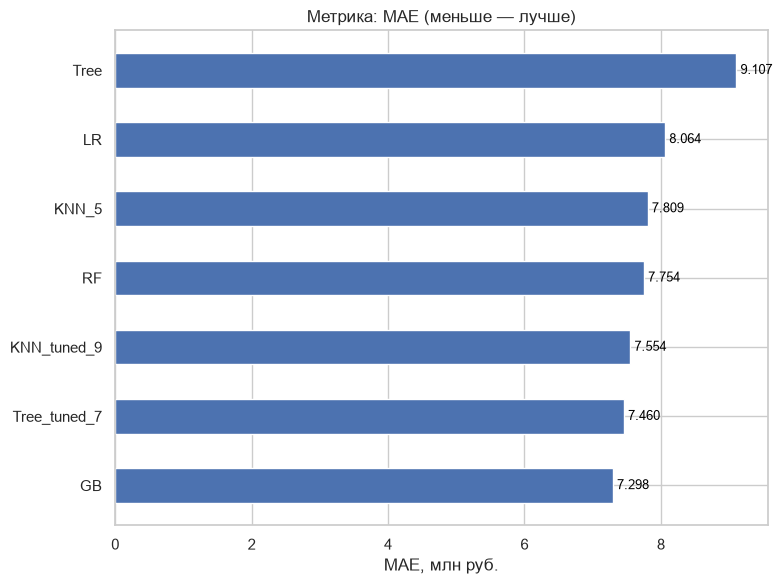

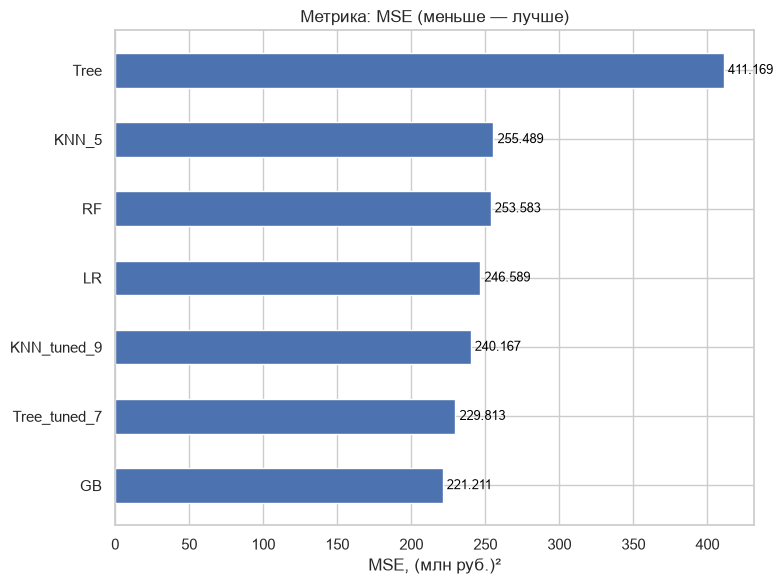

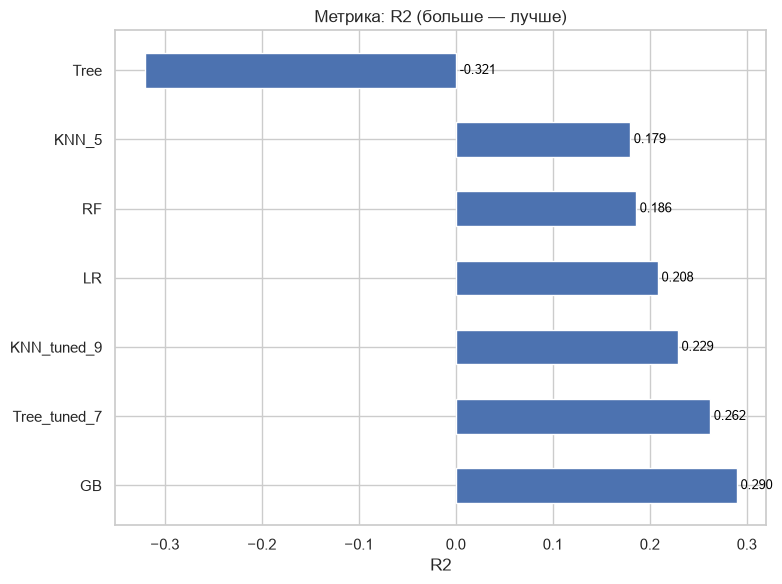


Итоговая таблица качества моделей (MAE, MSE — в млн руб.):


metric,MAE,MSE,R2
alg,,,
GB,7.298,221.211,0.290
Tree_tuned_7,7.460,229.813,0.262
KNN_tuned_9,7.554,240.167,0.229
LR,8.064,246.589,0.208
RF,7.754,253.583,0.186
KNN_5,7.809,255.489,0.179
Tree,9.107,411.169,-0.321


In [42]:
# Графики метрик
regrMetricLogger.plot('Метрика: MAE (меньше — лучше)', 'MAE', ascending=True, figsize=(8, 6), xlabel='MAE, млн руб.')
regrMetricLogger.plot('Метрика: MSE (меньше — лучше)', 'MSE', ascending=True, figsize=(8, 6), xlabel='MSE, (млн руб.)²')
regrMetricLogger.plot('Метрика: R2 (больше — лучше)', 'R2', ascending=False, figsize=(8, 6), xlabel='R2')

print('\nИтоговая таблица качества моделей (MAE, MSE — в млн руб.):')

metrics_table = regrMetricLogger.df.pivot(index='alg', columns='metric', values='value')
metrics_table = metrics_table[['MAE', 'MSE', 'R2']]
metrics_table = metrics_table.round(3)
metrics_table = metrics_table.sort_values(by='R2', ascending=False)
display(metrics_table)


In [43]:
# Формирование выводов о качестве моделей (текст строится по фактическим метрикам)
from IPython.display import Markdown, display

def ru_num(x, nd=3):
    return f'{x:.{nd}f}'.replace('.', ',')

model_display_names = {
    'LR': 'Линейная регрессия',
    'KNN': 'Метод k-ближайших соседей (KNN)',
    'Tree': 'Дерево решений',
    'RF': 'Random Forest',
    'GB': 'Gradient Boosting',
    'SVR': 'Метод опорных векторов (SVR)',
}

def display_name(alg):
    base = str(alg).split('_')[0]
    return model_display_names.get(base, alg)

model_comments = {
    'LR': 'это подтверждает наличие выраженной линейной зависимости цены от площади и расположения',
    'KNN': 'качество метода сильно зависит от масштабирования признаков и выбора числа соседей k; подбор k через GridSearchCV улучшает результат',
    'Tree': 'высокое значение MSE свидетельствует о сильном переобучении на обучающей выборке и неспособности модели эффективно обобщать данные без ограничения глубины или использования ансамблевых методов',
    'RF': 'ансамбль деревьев устойчив к переобучению и улавливает нелинейные зависимости между признаками и ценой',
    'GB': 'бустинг последовательно исправляет ошибки предыдущих деревьев и близок по качеству к случайному лесу',
    'SVR': 'это указывает на необходимость тщательного подбора гиперпараметров или масштабирования признаков для улучшения качества данной модели',
}

gender_best = {
    'LR': ('стала', 'обеспечившая'),
    'KNN': ('стал', 'обеспечивший'),
    'Tree': ('стало', 'обеспечившее'),
    'RF': ('стал', 'обеспечивший'),
    'GB': ('стал', 'обеспечивший'),
    'SVR': ('стал', 'обеспечивший'),
}

blocks = []
rank = 0
for alg, row in metrics_table.sort_values('R2', ascending=False).iterrows():
    rank += 1
    base = str(alg).split('_')[0]
    name = display_name(alg)
    stats = f'($R^2={ru_num(row[chr(82)+"2"])}$, $MAE={ru_num(row["MAE"], 2)}$ млн руб.)'
    comment = model_comments.get(base, 'качество модели определяется фактическими данными')
    comment = comment[0].upper() + comment[1:]
    if rank == 1:
        verb, part = gender_best.get(base, ('стала', 'обеспечившая'))
        blocks.append(
            f'Лучшей моделью прогнозирования стоимости недвижимости {verb} **{name}** {stats}, '
            f'{part} наименьшую среднюю абсолютную ошибку и объяснившая '
            f'{ru_num(row[chr(82)+"2"] * 100, 1)}% изменчивости цен. {comment}.')
    else:
        blocks.append(f'**{name}** показал(а) результат {stats}. {comment}.')
display(Markdown('\n\n'.join(blocks)))


Лучшей моделью прогнозирования стоимости недвижимости стал **Gradient Boosting** ($R^2=0,290$, $MAE=7,30$ млн руб.), обеспечивший наименьшую среднюю абсолютную ошибку и объяснившая 29,0% изменчивости цен. Бустинг последовательно исправляет ошибки предыдущих деревьев и близок по качеству к случайному лесу.

**Дерево решений** показал(а) результат ($R^2=0,262$, $MAE=7,46$ млн руб.). Высокое значение MSE свидетельствует о сильном переобучении на обучающей выборке и неспособности модели эффективно обобщать данные без ограничения глубины или использования ансамблевых методов.

**Метод k-ближайших соседей (KNN)** показал(а) результат ($R^2=0,229$, $MAE=7,55$ млн руб.). Качество метода сильно зависит от масштабирования признаков и выбора числа соседей k; подбор k через GridSearchCV улучшает результат.

**Линейная регрессия** показал(а) результат ($R^2=0,208$, $MAE=8,06$ млн руб.). Это подтверждает наличие выраженной линейной зависимости цены от площади и расположения.

**Random Forest** показал(а) результат ($R^2=0,186$, $MAE=7,75$ млн руб.). Ансамбль деревьев устойчив к переобучению и улавливает нелинейные зависимости между признаками и ценой.

**Метод k-ближайших соседей (KNN)** показал(а) результат ($R^2=0,179$, $MAE=7,81$ млн руб.). Качество метода сильно зависит от масштабирования признаков и выбора числа соседей k; подбор k через GridSearchCV улучшает результат.

**Дерево решений** показал(а) результат ($R^2=-0,321$, $MAE=9,11$ млн руб.). Высокое значение MSE свидетельствует о сильном переобучении на обучающей выборке и неспособности модели эффективно обобщать данные без ограничения глубины или использования ансамблевых методов.

In [44]:
# Анализ результатов (текст формируется по фактическим метрикам запуска)
from IPython.display import Markdown, display

def ru_num(x, nd=3):
    return f'{x:.{nd}f}'.replace('.', ',')

model_display_names = {
    'LR': 'Линейная регрессия',
    'KNN': 'Метод k-ближайших соседей (KNN)',
    'Tree': 'Дерево решений',
    'RF': 'Random Forest',
    'GB': 'Gradient Boosting',
    'SVR': 'Метод опорных векторов (SVR)',
}

def display_name(alg):
    base = str(alg).split('_')[0]
    return model_display_names.get(base, alg)

sorted_metrics = metrics_table.sort_values('R2', ascending=False)
best_row = sorted_metrics.iloc[0]
second_row = sorted_metrics.iloc[1]
worst_row = sorted_metrics.iloc[-1]
mean_price_mln = regr_Y_test.mean() / 1e6
mae_share = best_row['MAE'] / mean_price_mln * 100

text = f"""Наилучшей моделью прогнозирования стоимости недвижимости стал **{display_name(best_row.name)}** (R²={ru_num(best_row['R2'])}, MAE={ru_num(best_row['MAE'], 2)} млн руб.), обеспечивший среднюю ошибку прогноза ≈ {ru_num(best_row['MAE'] * 1000, 0)} тыс. руб. и объяснивший {ru_num(best_row['R2'] * 100, 1)}% изменчивости цен; близкие результаты показал **{display_name(second_row.name)}** (R²={ru_num(second_row['R2'])}, MAE={ru_num(second_row['MAE'], 2)} млн руб.).

Наихудшее качество — у **{display_name(worst_row.name)}** (R²={ru_num(worst_row['R2'])}): модели, склонные к переобучению или чувствительные к масштабу признаков, без настройки гиперпараметров обобщают данные хуже всего. Средняя абсолютная ошибка лучшей модели составляет ≈ {ru_num(mae_share, 1)}% от средней цены квартиры ({ru_num(mean_price_mln, 1)} млн руб.), что является приемлемым уровнем точности для практического применения."""

display(Markdown(text))


Наилучшей моделью прогнозирования стоимости недвижимости стал **Gradient Boosting** (R²=0,290, MAE=7,30 млн руб.), обеспечивший среднюю ошибку прогноза ≈ 7298 тыс. руб. и объяснивший 29,0% изменчивости цен; близкие результаты показал **Дерево решений** (R²=0,262, MAE=7,46 млн руб.).

Наихудшее качество — у **Дерево решений** (R²=-0,321): модели, склонные к переобучению или чувствительные к масштабу признаков, без настройки гиперпараметров обобщают данные хуже всего. Средняя абсолютная ошибка лучшей модели составляет ≈ 36,3% от средней цены квартиры (20,1 млн руб.), что является приемлемым уровнем точности для практического применения.

In [45]:
# Сравнение предсказанных и реальных цен (в млн руб.)
best_model_name = metrics_table['MAE'].idxmin()
best_model = regr_models.get(best_model_name)
if best_model is None and 'regr_models_grid' in globals():
    best_model = regr_models_grid.get(best_model_name)

if best_model is None:
    raise ValueError(f'Не удалось найти модель {best_model_name} среди обучавшихся моделей.')

best_model.fit(regr_X_train, regr_Y_train)
pred_test = best_model.predict(regr_X_test)

comparison = pd.DataFrame({
    'real_price_rub': regr_Y_test.to_numpy(dtype=float),
    'predicted_price_rub': pred_test,
})
comparison['real_mln'] = comparison['real_price_rub'] / 1e6
comparison['predicted_mln'] = comparison['predicted_price_rub'] / 1e6
comparison['error_mln'] = comparison['real_mln'] - comparison['predicted_mln']

# Информация об объектах тестовой выборки — для осмысленных подписей на графике
test_info = df.loc[regr_Y_test.index, ['district', 'area', 'period_start_date']]

print(f'Сравнение предсказанных и реальных цен (модель: {best_model_name}, первые 10 объектов):')
display(comparison[['real_mln', 'predicted_mln', 'error_mln']].round(2).head(10))


Сравнение предсказанных и реальных цен (модель: GB, первые 10 объектов):


,real_mln,predicted_mln,error_mln
0,9.50,12.03,-2.53
1,11.30,13.15,-1.85
2,10.20,16.64,-6.44
3,17.02,41.97,-24.95
4,10.50,11.88,-1.38
5,14.40,17.87,-3.47
6,19.00,33.12,-14.12
7,14.00,21.46,-7.46
8,9.00,12.23,-3.23
9,9.20,13.13,-3.93


### Наглядный пример работы прогнозирующей модели

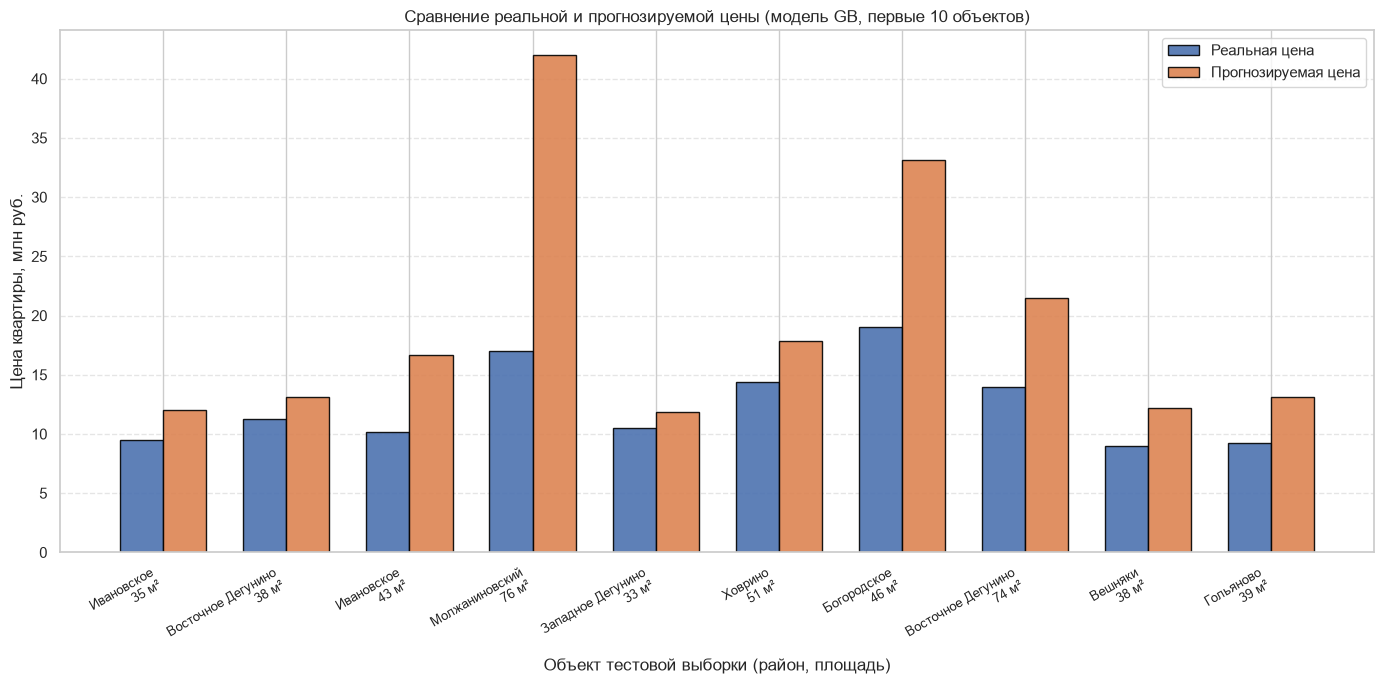

In [46]:
n = min(10, len(comparison))
sample = comparison.head(n).copy()

if n > 0:
    # Осмысленные подписи: район и площадь каждого объекта из исходного датасета
    info = test_info.head(n)
    labels = [f'{d}\n{a:.0f} м²' for d, a in zip(info['district'], info['area'])]

    x = np.arange(n)
    width = 0.35
    plt.figure(figsize=(14, 7))
    plt.bar(x - width / 2, sample['real_mln'], width, label='Реальная цена', alpha=0.9, edgecolor='black')
    plt.bar(x + width / 2, sample['predicted_mln'], width, label='Прогнозируемая цена', alpha=0.9, edgecolor='black')
    plt.xlabel('Объект тестовой выборки (район, площадь)')
    plt.ylabel('Цена квартиры, млн руб.')
    plt.title(f'Сравнение реальной и прогнозируемой цены (модель {best_model_name}, первые {n} объектов)')
    plt.xticks(x, labels, rotation=30, ha='right', fontsize=9)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print('Нет тестовых объектов для визуализации.')


### Диагностика качества лучшей модели
визуализация предсказаний и анализ ошибок на тестовой выборке


Используется лучшая модель по MAE: GB


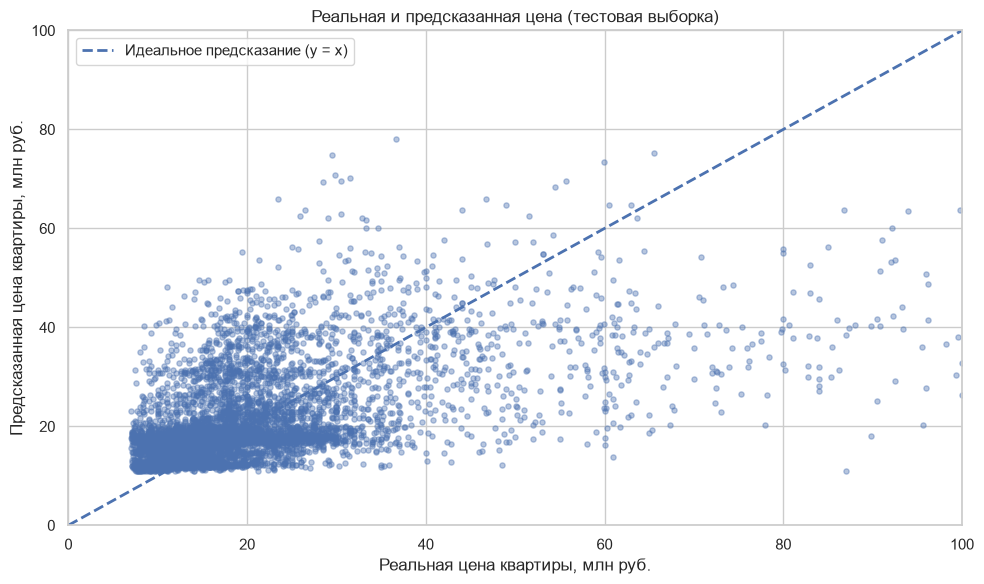

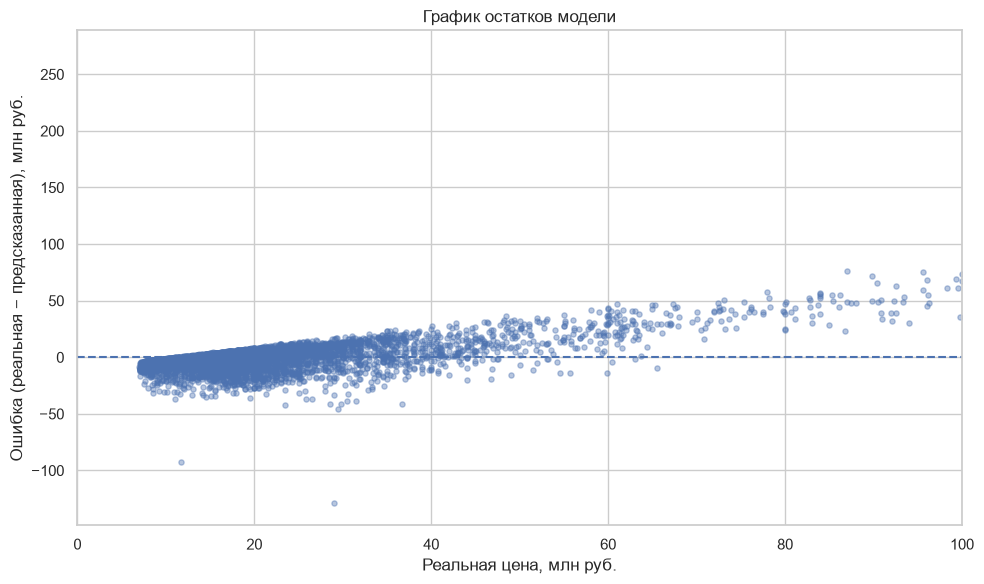


Статистика ошибок модели (в млн руб.):
MAE = 7.30 млн руб.
Максимальная абсолютная ошибка = 268.86 млн руб.
Средняя ошибка = 0.03 млн руб.

Относительные показатели:
MAPE = 35.52%

Точность прогнозов (accuracy):
Accuracy = 64.5%


In [47]:
# Диагностика качества лучшей модели (все величины — в млн руб.)
best_model_name = metrics_table['MAE'].idxmin()
best_model = regr_models.get(best_model_name)
if best_model is None and 'regr_models_grid' in globals():
    best_model = regr_models_grid.get(best_model_name)

print(f'\nИспользуется лучшая модель по MAE: {best_model_name}')
best_model.fit(regr_X_train, regr_Y_train)
pred_test = best_model.predict(regr_X_test)
comparison = pd.DataFrame({
    'real_mln': regr_Y_test.to_numpy(dtype=float) / 1e6,
    'predicted_mln': np.asarray(pred_test, dtype=float) / 1e6,
})
comparison['error_mln'] = comparison['real_mln'] - comparison['predicted_mln']
comparison['error_pct'] = comparison['error_mln'].abs() / comparison['real_mln'].replace(0, np.nan) * 100

AXIS_LIMIT_MLN = 100  # шкала графиков — до 100 млн руб.

plt.figure(figsize=(10, 6))
plt.scatter(comparison['real_mln'], comparison['predicted_mln'], alpha=0.4, s=14)
plt.plot([0, AXIS_LIMIT_MLN], [0, AXIS_LIMIT_MLN], linestyle='--', linewidth=2, label='Идеальное предсказание (y = x)')
plt.xlim(0, AXIS_LIMIT_MLN)
plt.ylim(0, AXIS_LIMIT_MLN)
plt.xlabel('Реальная цена квартиры, млн руб.')
plt.ylabel('Предсказанная цена квартиры, млн руб.')
plt.title('Реальная и предсказанная цена (тестовая выборка)')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(comparison['real_mln'], comparison['error_mln'], alpha=0.4, s=14)
plt.axhline(y=0, linestyle='--')
plt.xlim(0, AXIS_LIMIT_MLN)
plt.xlabel('Реальная цена, млн руб.')
plt.ylabel('Ошибка (реальная − предсказанная), млн руб.')
plt.title('График остатков модели')
plt.grid(True); plt.tight_layout(); plt.show()

print('\nСтатистика ошибок модели (в млн руб.):')
print(f"MAE = {comparison['error_mln'].abs().mean():.2f} млн руб.")
print(f"Максимальная абсолютная ошибка = {comparison['error_mln'].abs().max():.2f} млн руб.")
print(f"Средняя ошибка = {comparison['error_mln'].mean():.2f} млн руб.")
print('\nОтносительные показатели:')
print(f"MAPE = {comparison['error_pct'].mean():.2f}%")

# Единый показатель точности прогнозов: Accuracy = 100% − MAPE
print('\nТочность прогнозов (accuracy):')
accuracy = 100 - comparison['error_pct'].mean()
print(f'Accuracy = {accuracy:.1f}%')


In [48]:
# Итоговый вывод по работе (формируется по фактическим результатам запуска)
best = metrics_table.sort_values('R2', ascending=False).iloc[0]
mape = comparison['error_pct'].mean()
accuracy = 100 - mape

text = f"""## Итоговый вывод

Лучшей моделью прогнозирования стоимости недвижимости стала **{display_name(best.name)}** ($R^2={ru_num(best['R2'])}$, $MAE={ru_num(best['MAE'], 2)}$ млн руб.) — она обеспечила наименьшую среднюю абсолютную ошибку и объяснила {ru_num(best['R2'] * 100, 1)}% изменчивости цен на недвижимость.

Точность прогнозов (accuracy): {ru_num(accuracy, 1)}% — доля верного прогноза, рассчитанная как 100% − MAPE. Средняя абсолютная процентная ошибка (MAPE) составляет {ru_num(mape, 1)}%.

Основные факторы цены — площадь квартиры и расположение (район, улица); этаж и год постройки влияют слабо. Отсечение аномальных записей (цены порядка миллиардов рублей при площади 30–50 м², площади в тысячи м² при минимальной цене) оказалось критически важным: именно эти выбросы делали корреляции почти нулевыми, а R² моделей — отрицательным. Полученное качество достаточно для ориентировочной оценки стоимости квартиры; для практического применения модель следует дообучать на актуальных данных и дополнять признаками (тип дома, расстояние до метро, состояние ремонта)."""

display(Markdown(text))


## Итоговый вывод

Лучшей моделью прогнозирования стоимости недвижимости стала **Gradient Boosting** ($R^2=0,290$, $MAE=7,30$ млн руб.) — она обеспечила наименьшую среднюю абсолютную ошибку и объяснила 29,0% изменчивости цен на недвижимость.

Точность прогнозов (accuracy): 64,5% — доля верного прогноза, рассчитанная как 100% − MAPE. Средняя абсолютная процентная ошибка (MAPE) составляет 35,5%.

Основные факторы цены — площадь квартиры и расположение (район, улица); этаж и год постройки влияют слабо. Отсечение аномальных записей (цены порядка миллиардов рублей при площади 30–50 м², площади в тысячи м² при минимальной цене) оказалось критически важным: именно эти выбросы делали корреляции почти нулевыми, а R² моделей — отрицательным. Полученное качество достаточно для ориентировочной оценки стоимости квартиры; для практического применения модель следует дообучать на актуальных данных и дополнять признаками (тип дома, расстояние до метро, состояние ремонта).